# Chapter 5: Agentic RAG over documents and data

Companion notebook for [ch05/README.md](../README.md). Every number in the chapter comes from the
saved outputs below or from `eval/results/`.

Prerequisites: `.env` configured, the ShopFlow database running and seeded, Ollama serving
`nomic-embed-text`. The full eval is not re-run here (it takes ~25 minutes and costs money):
`eval/run_eval.py` wrote `eval/results/*.json`, and this notebook loads them. The live cells
below call `openai/gpt-6-luna` a handful of times (well under $0.01).

In [1]:
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from llmprod import connect, get_settings

from ch05_agentic import evalset
from ch05_agentic.tools import now_text

settings = get_settings()
IMAGES = Path("../images")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
print("run at:", now_text())
print({p: md.version(p) for p in ["langgraph", "langgraph-checkpoint", "openai", "sqlglot",
                                   "pgvector", "sentence-transformers", "psycopg"]})

run at: Monday 2026-11-09 09:20 (America/New_York)
{'langgraph': '1.2.20', 'langgraph-checkpoint': '4.3.1', 'openai': '3.46.0', 'sqlglot': '30.30.0', 'pgvector': '0.5.1', 'sentence-transformers': '6.2.0', 'psycopg': '3.3.8'}


## Setup: the documents go into Postgres

Chapter 4's recipe, copied into `previous_chapters.py`: heading-aware chunks, `nomic-embed-text`
embeddings (768-d) and a generated full-text column, in our own table `ch05_doc_chunks`.

In [2]:
import setup_db

print(setup_db.main())
with connect() as conn:
    print(conn.execute(
        "SELECT (SELECT count(*) FROM orders), (SELECT count(*) FROM shipments),"
        " (SELECT count(*) FROM support_tickets)").fetchone(),
        "<- orders, shipments, tickets")

{'chunker': 'heading', 'docs': 36, 'chunks': 316, 'seconds': 15.7, 'rows': 316}
(30433, 29138, 1560) <- orders, shipments, tickets


## The data: 25 questions that need both

`ch05_agentic/evalset.py` picks real rows for 25 templates and computes the gold facts with
hand-written SQL plus `policy.py` (the policies as code). The dev set is what we iterated on; the
held-out set uses the same templates on other rows and was only run at the end.

In [3]:
built_at, QS = evalset.load()
_, HOLD = evalset.load(Path("eval/questions_holdout.json"))
print("built at", built_at, "|", len(QS), "dev questions,", len(HOLD), "held-out")
same = [q.id for q, h in zip(QS, HOLD) if q.data["id"] == h.data["id"]]
print("held-out questions that reuse the dev row (only one row fits):", same)
pd.DataFrame([{"id": q.id, "template": q.template, "question": q.question} for q in QS])

built at 2026-11-09T08:32:07-05:00 | 25 dev questions, 25 held-out
held-out questions that reuse the dev row (only one row fits): ['a03', 't01']


,id,template,question
0,r01,return_open,Customer 1911 changed their mind about order 27414. Can they still return it...
1,r02,return_closed,Can customer 4226 still return order 21063?
2,r03,return_opened_beauty,Customer 3196 opened the Max Shampoo Bar from order 28429 and doesn't like i...
3,r04,damaged_opened_grocery,The Eco Dark Chocolate Bar in order 27559 arrived damaged and customer 2878 ...
4,c01,cancel_paid,"Customer 4591 wants to cancel order 30390. Is that possible, and how much do..."
5,c02,cancel_shipped,The customer changed their mind. Can order 29945 still be cancelled?
6,c03,pending_autocancel,"Order 29987 is still pending. Was the customer charged, and what happens to ..."
7,w01,warranty_electronics,The Everyday USB-C Hub from order 3373 stopped charging. Customer 2387 wants...
8,w02,warranty_expired,The Classic Trail Runner from order 9700 has a manufacturing defect. Is it s...
9,w03,warranty_90_open,Customer 3843 reports a defect in the Eco Plush Fox from order 18160. Can we...


In [4]:
HEADLINE = next(q for q in QS if q.id == "r02")
print(HEADLINE.question)
print("gold:", HEADLINE.gold)
print("facts behind it:", {k: HEADLINE.data[k] for k in ("delivered_at", "category", "days")})

Can customer 4226 still return order 21063?
gold: ['No, the 30-day return window has closed (delivered 2026-09-21, 49 days ago)']
facts behind it: {'delivered_at': '2026-09-21T22:44:14.037278-04:00', 'category': 'Books', 'days': 49}


## v0: Chapter 4's pipeline

Retrieve five chunks for the question, answer from them. It has no way to look up an order.

In [5]:
from ch05_agentic.llm import LLM
from ch05_agentic.tools import DocSearch
from ch05_agentic.variants import GraphAgent, ch04_rag, tool_loop

llm, docs = LLM("openai/gpt-6-luna"), DocSearch()
spent = []
r = ch04_rag(HEADLINE.question, llm, docs)
spent.append(r.usage["cost_usd"])
print(r.answer)
print("retrieved:", r.evidence)

/home/a.saugi/llm-in-production/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 19505.80it/s]

I can’t determine whether customer 4226 can still return order 21063 because the context does not include either order’s delivery date, items, or return status. Most items are returnable within 30 days of delivery, if unused and in original packaging; opened beauty products and grocery items are excluded unless damaged or defective. [doc:faq.md#3]
retrieved: ['[doc:faq.md#1]', '[doc:faq.md#3]', '[doc:policies/returns-policy.md#0]', '[doc:policies/returns-policy.md#5]', '[doc:policies/account-security.md#5]', '[doc:policies/order-cancellation.md#5]', '[doc:handbook/support-escalation.md#8]', '[doc:policies/shipping-policy.md#6]', '[doc:handbook/metrics-glossary.md#4]', '[doc:handbook/refund-approval-limits.md#2]']


## v1: a plain tool loop

Two tools (`search_docs`, `run_sql`) and a `for` loop around Chat Completions.

In [6]:
r = tool_loop(HEADLINE.question, llm, docs)
spent.append(r.usage["cost_usd"])
for s in r.steps:
    print(s)
print()
print(r.answer)
print(f"\n{r.latency_ms} ms, {r.usage['calls']} LLM calls, ${r.usage['cost_usd']:.5f}")

{'step': 'run_sql', 'args': '{"sql":"SELECT o.id AS order_id, o.customer_id, o.status, (s.delivered_at AT TIME ZONE \'America/New_York\') AS delivered_at_local, (now() AT TIME ZONE \'America/New_York\')::date - (s.delivered_at AT TIME ZONE \'America/New_York\')::date AS days_since_delivery FROM orders o LEFT JOIN shipments s ON s.ord'}
{'step': 'search_docs', 'args': '{"query":"return window number of days after delivery return eligibility policy unused condition"}'}

No—the order was delivered on 2026-09-21, and 49 days have elapsed as of 2026-11-09, beyond the 30-day return window. [sql:1] Items generally must be returned within 30 days of delivery, unused and in their original packaging; the category-specific rules may also apply. [doc:policies/returns-policy.md#1]

4405 ms, 2 LLM calls, $0.00042


OpenAI's docs say gpt-6-luna supports function calling on Chat Completions only with
`reasoning_effort="none"`. Through OpenRouter, with `require_parameters` so nothing is silently
dropped:

In [7]:
from llmprod import chat_client

from ch05_agentic.variants import TOOLS

client = chat_client()
for effort in ("none", "low", None):
    kw = {"reasoning_effort": effort} if effort else {}
    resp = client.chat.completions.create(
        model="openai/gpt-6-luna", max_tokens=600, tools=TOOLS,
        messages=[{"role": "user", "content": "Look up order 21461's delivery date."}],
        extra_body={"provider": {"require_parameters": True}}, **kw)
    m = resp.choices[0].message
    spent.append(resp.usage.cost)
    print(f"reasoning_effort={effort!s:5} tool_calls={[t.function.name for t in m.tool_calls or []]}"
          f" completion_tokens={resp.usage.completion_tokens}")

reasoning_effort=none  tool_calls=['run_sql'] completion_tokens=31


reasoning_effort=low   tool_calls=['run_sql'] completion_tokens=31


reasoning_effort=None  tool_calls=['run_sql'] completion_tokens=31


## v2: the LangGraph agent

The graph LangGraph compiled from `ch05_agentic/graph.py`, as Mermaid:

In [8]:
from ch05_agentic.graph import build_graph

print(build_graph(llm, docs).get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	route(route)
	retrieve(retrieve)
	sql(sql)
	grade(grade)
	rewrite(rewrite)
	answer(answer)
	__end__([<p>__end__</p>]):::last
	__start__ --> route;
	grade -.-> answer;
	grade -.-> rewrite;
	retrieve --> grade;
	rewrite -.-> answer;
	rewrite -.-> retrieve;
	rewrite -.-> sql;
	route -.-> answer;
	route -.-> retrieve;
	route -.-> sql;
	sql --> grade;
	answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [9]:
from cli import stream_graph

stream_graph(HEADLINE.question, llm, docs)

[route     2729 ms] doc_query='return eligibility window and exceptions' sql_question='For customer 4226 and order 21063, fetch the order status, delivery date, items and product categories, amounts, customer segment, and country; confirm the order belongs to this customer.'
[retrieve    55 ms] [doc:handbook/support-tone-guide.md#7] [doc:handbook/refund-approval-limits.md#6] [doc:policies/returns-policy.md#8] [doc:policies/returns-policy.md#1]


[sql       3378 ms] [sql:1] 1 row(s)


[grade     1422 ms] sufficient=True relevant=['[sql:1]', '[doc:policies/returns-policy.md#1]', '[doc:policies/returns-policy.md#8]', '[doc:handbook/refund-approval-limits.md#6]']


[answer    3986 ms] 

No. Order 21063 belongs to customer 4226 and contains a $13.99 book item; it was delivered September 21, 2026, and 49 days have elapsed as of November 9 (September 21 + 30 days = October 21), so it is past the 30-day return limit. [sql:1] [doc:policies/returns-policy.md#1]

total 11519 ms, model=openai/gpt-6-luna


### The same graph on a local model (optional)

Set `RUN_LOCAL=1` to run the headline question on `qwen3:8b` through Ollama. It is off by
default so the notebook runs without a local GPU model. The saved output below is from the
2026-11-09 run on a shared RTX 3090; the full qwen3:8b eval is in the Results tables and the README.

In [10]:
import os

if os.environ.get("RUN_LOCAL") == "1":
    local = GraphAgent(LLM("qwen3:8b"), docs)(HEADLINE.question)
    print(local.answer)
    print(f"\n{local.latency_ms} ms, {local.usage['calls']} LLM calls, error={local.error}")
else:
    print("RUN_LOCAL is not set: skipping the local qwen3:8b run.")

Yes, customer 4226 can still return order 21063. The order was delivered on 2026-09-21, and today is 2026-11-09, which is 49 days since delivery. The return window is 30 days from delivery, so the customer has 30 days from 2026-09-21, which ends on 2026-10-20. Since today is 2026-11-09, the customer is past the return window [sql:1].

5088 ms, 4 LLM calls, error=None


## Checkpoints: resume instead of restart

We make the `answer` node fail once (a stand-in for a provider timeout), then resume the same
thread. LangGraph saved the state after every superstep, so only `answer` runs again.

In [11]:
import uuid

from langgraph.checkpoint.memory import InMemorySaver

from ch05_agentic.graph import initial_state


class FlakyAnswer(LLM):
    """The real model, except the first `answer` call raises. Every LLM call goes through
    `text`, so `steps` records each one."""

    failed = False
    steps: list = []

    def text(self, messages, usage, step, **kw):
        self.steps.append(step)
        if step == "answer" and not self.failed:
            self.failed = True
            raise TimeoutError("simulated provider timeout")
        return super().text(messages, usage, step, **kw)


flaky = FlakyAnswer("openai/gpt-6-luna")
app = build_graph(flaky, docs, checkpointer=InMemorySaver())
config = {"configurable": {"thread_id": uuid.uuid4().hex}}
try:
    app.invoke(initial_state(HEADLINE.question, now_text()), config)
except TimeoutError as e:
    print("run 1 failed:", e, "| LLM steps so far:", flaky.steps)
snap = app.get_state(config)
print("next node to run:", snap.next, "| evidence saved:", [e["citation"] for e in snap.values["evidence"]])
state = app.invoke(None, config)
print("run 2 (resumed) LLM steps:", flaky.steps)
print(state["answer"])
spent.append(sum(c["cost_usd"] for c in state["llm_calls"]))
history = list(app.get_state_history(config))
print(f"\n{len(history)} checkpoints in this thread, newest first:")
for h in history:
    print(f"  step {h.metadata.get('step'):>2}  next={h.next}")

run 1 failed: simulated provider timeout | LLM steps so far: ['route', 'sql_plan', 'grade', 'answer']
next node to run: ('answer',) | evidence saved: ['[doc:handbook/support-escalation.md#8]', '[doc:handbook/refund-approval-limits.md#6]', '[doc:policies/price-adjustment-policy.md#7]', '[doc:policies/returns-policy.md#1]', '[sql:1]']


run 2 (resumed) LLM steps: ['route', 'sql_plan', 'grade', 'answer', 'answer']
No, the 30-day return window has passed: the order was delivered on 2026-09-21, and 30 days later was 2026-10-21; today is 2026-11-09, 49 days after delivery. [sql:1] [doc:handbook/support-escalation.md#8] The order contains one Books item, Premium Notebook A5, priced at $13.99; the order total was $19.98, including $5.99 shipping. [sql:1] Returns also require the item to be unused and in original packaging, but its condition is not provided. [doc:policies/returns-policy.md#1] Since returns after 30 days are not eligible for approval, escalate any exception to a team lead. [doc:handbook/refund-approval-limits.md#6]

6 checkpoints in this thread, newest first:
  step  4  next=()
  step  3  next=('answer',)
  step  2  next=('grade',)
  step  1  next=('retrieve', 'sql')
  step  0  next=('route',)
  step -1  next=('__start__',)


## Results

`eval/run_eval.py` ran every variant on the 25 dev questions and on the 25 held-out questions,
judged by `anthropic/claude-haiku-5.5` against the gold facts. The tool loop and the graph ran
three times on the dev set (`-r2`, `-r3`), because a single run of 25 questions moves by several
questions from run to run. Two eval processes ran at the same time. Runs from before the shared
database was re-seeded are archived in `eval/results/pre-reseed/` and not used here.

In [12]:
import re

rows = []
for f in sorted(Path("eval/results").glob("*.json")):
    if f.name == "judge_check.json":
        continue
    s = json.loads(f.read_text())["summary"]
    s["set"] = "held-out" if "holdout" in f.stem else "dev"
    m = re.search(r"-r(\d)$", f.stem)
    s["run"] = int(m.group(1)) if m else 1
    s["file"] = f.name
    rows.append(s)
runs = pd.DataFrame(rows)
order = {"ch04_rag": 0, "tool_loop": 1, "graph": 2}
cols = ["set", "model", "variant", "run", "accuracy", "facts_ok", "gold_doc_retrieved",
        "cites_doc_and_sql", "invalid_citations", "sql_errors", "errors", "p50_ms", "p95_ms",
        "mean_llm_calls", "usd_per_1k"]
runs = runs.sort_values(["set", "model", "variant", "run"],
                        key=lambda c: c.map(order) if c.name == "variant" else c)
runs[cols].reset_index(drop=True)

,set,model,variant,run,accuracy,facts_ok,gold_doc_retrieved,cites_doc_and_sql,invalid_citations,sql_errors,errors,p50_ms,p95_ms,mean_llm_calls,usd_per_1k
0,dev,openai/gpt-6-luna,ch04_rag,1,12.0,19.5,88.0,0.0,0,0,0,1815,2590,1.00,0.2682
1,dev,openai/gpt-6-luna,tool_loop,1,84.0,90.2,96.0,100.0,0,0,0,6066,9068,2.60,0.5948
2,dev,openai/gpt-6-luna,tool_loop,2,60.0,75.6,100.0,100.0,0,0,0,4699,7399,2.40,0.5505
3,dev,openai/gpt-6-luna,tool_loop,3,72.0,82.9,96.0,100.0,0,0,0,4805,7863,2.44,0.5632
4,dev,openai/gpt-6-luna,graph,1,72.0,82.9,92.0,100.0,0,0,0,9778,29561,6.24,1.3972
5,dev,openai/gpt-6-luna,graph,2,80.0,85.4,96.0,100.0,0,0,0,10680,27830,6.16,1.3408
6,dev,openai/gpt-6-luna,graph,3,80.0,87.8,92.0,96.0,0,0,0,12612,28108,5.84,1.3897
7,dev,qwen3:8b,ch04_rag,1,12.0,26.8,88.0,0.0,1,0,0,1775,2535,1.00,0.0000
8,dev,qwen3:8b,tool_loop,1,0.0,12.2,20.0,0.0,4,0,0,1192,1917,2.12,0.0000
9,dev,qwen3:8b,graph,1,32.0,34.1,80.0,12.0,0,10,0,5135,20268,5.84,0.0000


In [13]:
agg = (runs.groupby(["set", "model", "variant"], sort=False)
       .agg(runs=("run", "count"), acc_mean=("accuracy", "mean"), acc_min=("accuracy", "min"),
            acc_max=("accuracy", "max"), facts=("facts_ok", "mean"), p50_s=("p50_ms", "median"),
            p95_s=("p95_ms", "median"), calls=("mean_llm_calls", "mean"), usd_per_1k=("usd_per_1k", "mean"))
       .reset_index())
agg["p50_s"] = (agg.p50_s / 1000).round(1)
agg["p95_s"] = (agg.p95_s / 1000).round(1)
agg.round({"acc_mean": 1, "facts": 1, "calls": 2, "usd_per_1k": 3})

,set,model,variant,runs,acc_mean,acc_min,acc_max,facts,p50_s,p95_s,calls,usd_per_1k
0,dev,openai/gpt-6-luna,ch04_rag,1,12.0,12.0,12.0,19.5,1.8,2.6,1.00,0.268
1,dev,openai/gpt-6-luna,tool_loop,3,72.0,60.0,84.0,82.9,4.8,7.9,2.48,0.570
2,dev,openai/gpt-6-luna,graph,3,77.3,72.0,80.0,85.4,10.7,28.1,6.08,1.376
3,dev,qwen3:8b,ch04_rag,1,12.0,12.0,12.0,26.8,1.8,2.5,1.00,0.000
4,dev,qwen3:8b,tool_loop,1,0.0,0.0,0.0,12.2,1.2,1.9,2.12,0.000
5,dev,qwen3:8b,graph,1,32.0,32.0,32.0,34.1,5.1,20.3,5.84,0.000
6,held-out,openai/gpt-6-luna,ch04_rag,1,8.0,8.0,8.0,19.5,1.8,3.0,1.00,0.255
7,held-out,openai/gpt-6-luna,tool_loop,1,80.0,80.0,80.0,87.8,5.7,9.6,2.44,0.583
8,held-out,openai/gpt-6-luna,graph,1,84.0,84.0,84.0,90.2,11.4,35.0,5.88,1.482


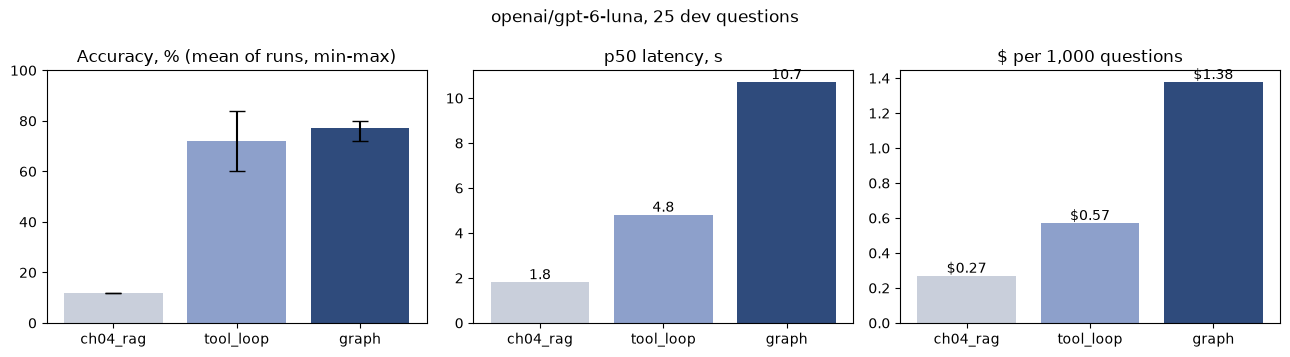

In [14]:
luna = agg[(agg.model == "openai/gpt-6-luna") & (agg.set == "dev")].set_index("variant").loc[list(order)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
colors = ["#c9cfdb", "#8da0cb", "#2f4b7c"]
err = [luna.acc_mean - luna.acc_min, luna.acc_max - luna.acc_mean]
axes[0].bar(luna.index, luna.acc_mean, yerr=err, capsize=6, color=colors)
axes[0].set_title("Accuracy, % (mean of runs, min-max)")
axes[0].set_ylim(0, 100)
for ax, col, title, fmt in ((axes[1], "p50_s", "p50 latency, s", "{:.1f}"),
                            (axes[2], "usd_per_1k", "$ per 1,000 questions", "${:.2f}")):
    ax.bar(luna.index, luna[col], color=colors)
    ax.set_title(title)
    for i, v in enumerate(luna[col]):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom")
fig.suptitle("openai/gpt-6-luna, 25 dev questions")
fig.tight_layout()
fig.savefig(IMAGES / "05-results.png", dpi=150)
plt.show()

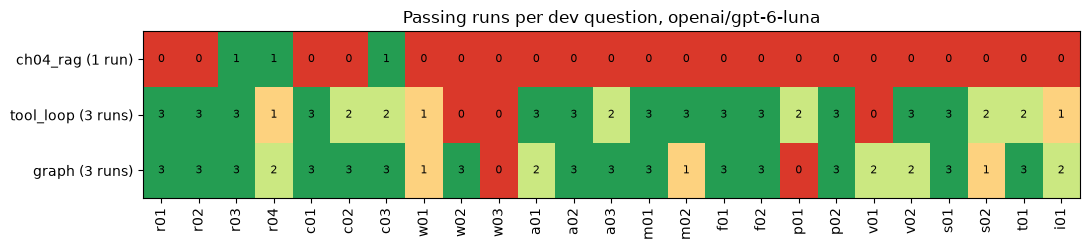

questions that passed in some runs but not all: {'ch04_rag': 0, 'tool_loop': 9, 'graph': 8}


In [15]:
def passes(path):
    return {r["id"]: int(r["judge"]["pass"]) for r in json.loads(Path(path).read_text())["rows"]}


files = {v: [f for t in ("", "-r2", "-r3")
             if (f := Path(f"eval/results/{v}-openai_gpt-6-luna{t}.json")).exists()] for v in order}
grid = pd.DataFrame({v: sum(pd.Series(passes(f)) for f in fs) for v, fs in files.items()})
share = grid / pd.Series({v: len(fs) for v, fs in files.items()})
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.imshow(share.T.values, cmap="RdYlGn", vmin=-0.15, vmax=1.15, aspect="auto")
for (i, j), v in pd.DataFrame(grid.T.values).stack().items():
    ax.text(j, i, v, ha="center", va="center", fontsize=8)
ax.set_yticks(range(len(order)), [f"{v} ({len(files[v])} run{'s' * (len(files[v]) > 1)})" for v in order])
ax.set_xticks(range(len(grid)), grid.index, rotation=90)
ax.set_title("Passing runs per dev question, openai/gpt-6-luna")
fig.tight_layout()
fig.savefig(IMAGES / "05-per-question.png", dpi=150)
plt.show()
flaky = grid[(share > 0) & (share < 1)].count()
print("questions that passed in some runs but not all:", flaky.to_dict())

### Where the graph spends its calls, and why it loops

In [16]:
loops = []
for t in ("", "-r2", "-r3"):
    for r in json.loads(Path(f"eval/results/graph-openai_gpt-6-luna{t}.json").read_text())["rows"]:
        grades = [s["grade"] for s in r["result"]["steps"] if "grade" in s]
        loops.append({"run": t or "-r1", "id": r["id"], "pass": r["judge"]["pass"],
                      "llm_calls": r["result"]["usage"]["calls"], "rewrites": max(0, len(grades) - 1),
                      "latency_s": round(r["result"]["latency_ms"] / 1000, 1),
                      "first 'missing'": grades[0]["missing"][:90] if grades else ""})
loops = pd.DataFrame(loops)
print(loops.rewrites.value_counts().sort_index().to_dict(), "<- graph runs (75) by number of rewrites")
for k, grp in loops.groupby(loops.rewrites > 0):
    print(f"{'with rewrites' if k else 'no rewrite  '}: n={len(grp):2}  accuracy={100 * grp['pass'].mean():.1f}%"
          f"  median latency={grp.latency_s.median():.1f} s  mean calls={grp.llm_calls.mean():.1f}")
loops[loops.rewrites > 0].head(12)

{0: 42, 1: 14, 2: 19} <- graph runs (75) by number of rewrites
no rewrite  : n=42  accuracy=83.3%  median latency=8.9 s  mean calls=4.0
with rewrites: n=33  accuracy=69.7%  median latency=21.4 s  mean calls=8.7


,run,id,pass,llm_calls,rewrites,latency_s,first 'missing'
0,-r1,r01,True,6,1,9.3,"Look up the return policy for the order's Home & Kitchen product category, i..."
7,-r1,w01,True,6,1,11.5,Look up the warranty period applicable to the Everyday USB-C Hub and its cov...
8,-r1,w02,True,9,2,17.7,"Look up the applicable warranty period’s start date, specifically the order’..."
10,-r1,a01,False,11,2,23.1,Look up the refund approval thresholds and who is authorized to approve a $4...
11,-r1,a02,True,6,1,9.8,"Look up the refund approval limits by amount and customer segment, and deter..."
12,-r1,a03,True,8,2,12.8,Look up the refund approval limits and approver rules for a full refund of t...
16,-r1,f02,True,10,2,28.9,Look up whether the customer reported the defect within 30 days of delivery ...
17,-r1,p01,False,11,2,29.6,Look up when payment for order 29717 succeeded and whether this item has alr...
18,-r1,p02,True,12,2,34.4,Look up whether the price actually fell within 7 days of the successful paym...
22,-r1,s02,False,10,2,20.0,Look up whether order 9085 was eligible for free shipping under the applicab...


### Graph failures in run 1, with the judge's reasons

In [17]:
g = json.loads(Path("eval/results/graph-openai_gpt-6-luna.json").read_text())
for r in g["rows"]:
    if not r["judge"]["pass"]:
        print(f"{r['id']} {r['template']}\n  gold:   {r['gold']}\n  answer: {r['result']['answer'][:400]}"
              f"\n  judge:  {r['judge']['reason'][:300]}\n")

r04 damaged_opened_grocery
  gold:   ['It is still eligible: damaged grocery items qualify even if opened (reported within 30 days of delivery)', 'A free replacement or a full refund including shipping (the order total is $38.37)']
  answer: Offer a free replacement or a full refund including shipping, at the customer’s choice. The item is grocery, so opened status does not affect eligibility; it was delivered 2026-10-27, and 30 days later is 2026-11-26, so the customer must contact support by then and include a photo. [doc:policies/returns-policy.md#7] The order was delivered, the item amount is $35.98, and no refund, replacement, or
  judge:  Fact 1: The answer states opened status does not affect eligibility and the 30-day window is computed (delivered 2026-10-27, deadline 2026-11-26), so it is stated. Fact 2: The answer offers a free replacement or full refund but explicitly says the refund amount is not established and doesn't state t

w03 warranty_90_open
  gold:   ['The 30-day r

### Can we trust the judge?

`eval/judge_check.py` re-graded the first 12 run-1 dev answers of the graph with
`anthropic/claude-sonnet-5.5` (a sample, to stay inside the chapter's budget).

In [18]:
jc = json.loads(Path("eval/results/judge_check.json").read_text())
print(f"haiku vs sonnet agreement: {jc['agree']}/{jc['n']} = {jc['agreement']}% (sonnet cost ${jc['strong_cost_usd']:.4f})")
for r in jc["rows"]:
    if r["cheap"] != r["strong"]:
        print(f"\n{r['file']} {r['id']}: haiku={r['cheap']} sonnet={r['strong']}")
        print("  haiku: ", r["cheap_reason"][:250])
        print("  sonnet:", r["strong_reason"][:250])

haiku vs sonnet agreement: 10/12 = 83.3% (sonnet cost $0.0385)

graph-openai_gpt-6-luna.json r04: haiku=False sonnet=True
  haiku:  Fact 1: The answer states opened status does not affect eligibility and the 30-day window is computed (delivered 2026-10-27, deadline 2026-11-26), so it is stated. Fact 2: The answer offers a free replacement or full refund but explicitly says the re
  sonnet: Fact 1: the answer says grocery opened status does not affect eligibility and gives the 30-day window from delivery (Oct 27 + 30 = Nov 26, shown), so it is stated. Fact 2: the answer offers a free replacement or a full refund including shipping, but 

graph-openai_gpt-6-luna.json a01: haiku=False sonnet=True
  haiku:  Fact 1: answer states the $47.96 full refund including shipping, matching the gold amount. Fact 2: answer says a support agent can approve it but does not state the $100.00 limit; the fact as written requires the approval ceiling of $100.00 to be sta
  sonnet: Fact 1: the answer states 

## What this notebook spent

In [19]:
print(f"live cells in this notebook: ${sum(spent):.5f}")
total = 0.0
for f in sorted(Path("eval/results").rglob("*.json")):
    d = json.loads(f.read_text())
    if f.name == "judge_check.json":
        c = d["strong_cost_usd"]
    else:
        c = d["summary"]["total_cost_usd"] + d["summary"]["judge_cost_usd"]
    total += c
    print(f"{str(f.relative_to('eval/results')):60} ${c:.4f}")
print(f"{'all saved eval runs (including development and pre-reseed runs)':60} ${total:.4f}")

live cells in this notebook: $0.00168
ch04_rag-openai_gpt-6-luna-holdout.json                      $0.0101
ch04_rag-openai_gpt-6-luna.json                              $0.0104
ch04_rag-qwen3-8b.json                                       $0.0041
graph-openai_gpt-6-luna-holdout.json                         $0.0408
graph-openai_gpt-6-luna-r2.json                              $0.0372
graph-openai_gpt-6-luna-r3.json                              $0.0385
graph-openai_gpt-6-luna.json                                 $0.0388
graph-qwen3-8b.json                                          $0.0038
judge_check.json                                             $0.0385
pre-reseed/ch04_rag-openai_gpt-6-luna-dev1.json              $0.0059
pre-reseed/ch04_rag-openai_gpt-6-luna-holdout.json           $0.0099
pre-reseed/ch04_rag-openai_gpt-6-luna-r3.json                $0.0100
pre-reseed/ch04_rag-openai_gpt-6-luna.json                   $0.0062
pre-reseed/ch04_rag-qwen_qwen3.8-flash.json                  $0.0